In [23]:
import pandas as pd

df_ames_raw = pd.read_excel(r"C:\Users\momoj\Desktop\Data sinence\AmesHousing.xlsx")
interestingFeatures = ["Order", "Lot Area",
"Gr Liv Area", "Full Bath",
"Half Bath","Total Bsmt SF", "1st Flr SF",
"2nd Flr SF","Bedroom AbvGr", "TotRms AbvGrd",
"Yr Sold","Mo Sold", "SalePrice"]

df_ames = df_ames_raw[interestingFeatures]
df_ames.head()

,Order,Lot Area,Gr Liv Area,Full Bath,Half Bath,Total Bsmt SF,1st Flr SF,2nd Flr SF,Bedroom AbvGr,TotRms AbvGrd,Yr Sold,Mo Sold,SalePrice
0,1,31770,1656,1,0,1080.0,1656,0,3,7,2010,5,215000
1,2,11622,896,1,0,882.0,896,0,2,5,2010,6,105000
2,3,14267,1329,1,1,1329.0,1329,0,3,6,2010,6,172000
3,4,11160,2110,2,1,2110.0,2110,0,3,8,2010,4,244000
4,5,13830,1629,2,1,928.0,928,701,3,6,2010,3,189900


,min,median,mean,max,std
SalePrice,12789.0,160000.0,180796.060068,755000.0,79886.692357


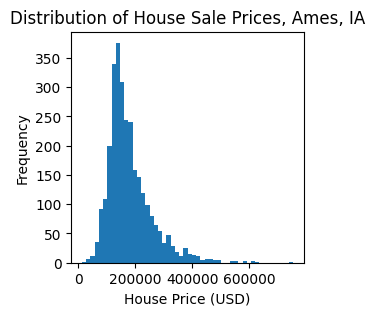

In [24]:
df_ames.SalePrice.plot.hist(bins=50, xlabel = 'House Price (USD)',
                                title = 'Distribution of House Sale Prices, Ames, IA',
                            figsize=(3,3))
df_ames.SalePrice.aggregate(['min','median','mean','max', 'std']).to_frame().T

In [45]:
df_ames.tail()

,Order,Lot Area,Gr Liv Area,Full Bath,Half Bath,Total Bsmt SF,1st Flr SF,2nd Flr SF,Bedroom AbvGr,TotRms AbvGrd,Yr Sold,Mo Sold,SalePrice
2925,2926,7937,1003,1,0,1003.0,1003,0,3,6,2006,3,142500
2926,2927,8885,902,1,0,864.0,902,0,2,5,2006,6,131000
2927,2928,10441,970,1,0,912.0,970,0,3,6,2006,7,132000
2928,2929,10010,1389,1,0,1389.0,1389,0,2,6,2006,4,170000
2929,2930,9627,2000,2,1,996.0,996,1004,3,9,2006,11,188000


,min,median,mean,max,std
Gr Liv Area,334.0,1442.0,1499.690444,5642.0,505.508887


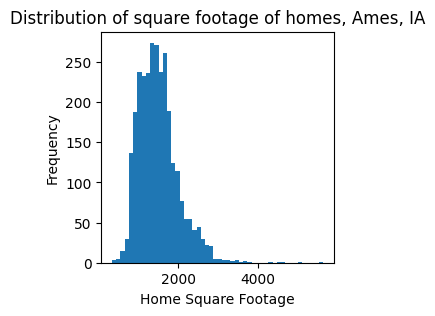

In [25]:
df_ames['Gr Liv Area'].plot.hist(bins=50,
xlabel = 'Home Square Footage',
title = 'Distribution of square footage of homes, Ames, IA',
figsize = (3,3))
df_ames['Gr Liv Area'].aggregate(['min','median','mean','max', 'std']).to_frame().T

In [26]:
df_ames['Gr Liv Area'].std(ddof=0)

np.float64(505.42261579508)

In [27]:
df_ames[(df_ames['Gr Liv Area'] >= 1000)  & (df_ames['Gr Liv Area']<= 2000)].Order.count(), df_ames.Order.count()

(np.int64(2090), np.int64(2930))

In [28]:
home = df_ames.iloc[100][['Gr Liv Area','SalePrice']]
home.to_frame().T

,Gr Liv Area,SalePrice
100,1573.0,177500.0


<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

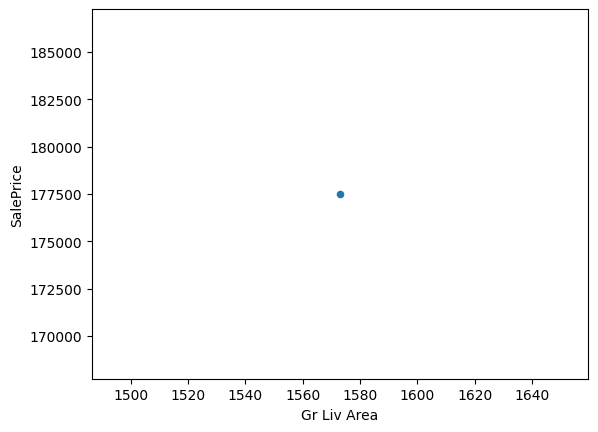

In [29]:
home.to_frame().T.plot.scatter(x='Gr Liv Area', y='SalePrice')

matplotlib.axes._axes.Axes

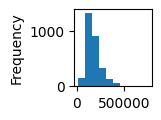

In [30]:
type(df_ames.SalePrice.plot.hist(figsize = (1,1)))

Axes(0.125,0.11;0.775x0.77)


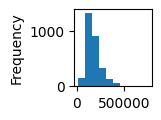

In [31]:
axx = df_ames.SalePrice.plot.hist(figsize = (1,1))
print(axx)

<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

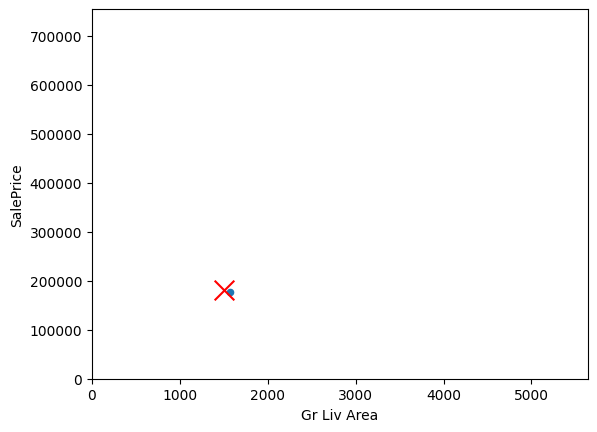

In [32]:
axx = home.to_frame().T.plot.scatter(x='Gr Liv Area', y='SalePrice',
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max())
                               )
means = df_ames[['Gr Liv Area', 'SalePrice']].mean()
means
means.to_frame().T.plot.scatter(x='Gr Liv Area', y='SalePrice',
                              c='red', marker = 'x', s = 200,
                              ax =axx)

<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

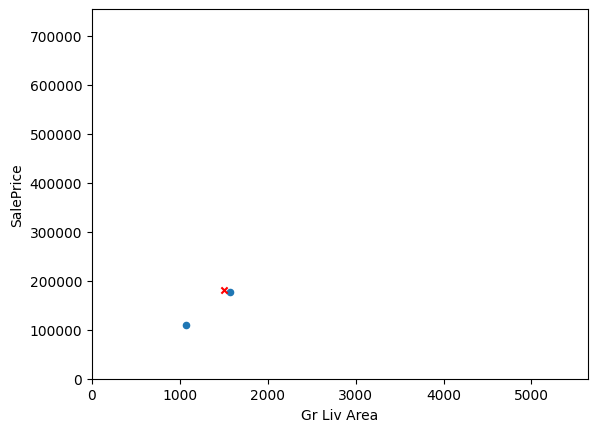

In [33]:
homes_of_interest = [100, 200]
home = df_ames.iloc[homes_of_interest ][['Gr Liv Area','SalePrice']]
home
axx = home.plot.scatter(x='Gr Liv Area', y='SalePrice',
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max())
                               )
means.to_frame().T.plot.scatter(x='Gr Liv Area', y='SalePrice',c='red', marker = 'x', ax =axx)

<Axes: title={'center': 'Price vs. Home size (sq. ft.) for Selected Homes'}, xlabel='Gr Liv Area', ylabel='SalePrice'>

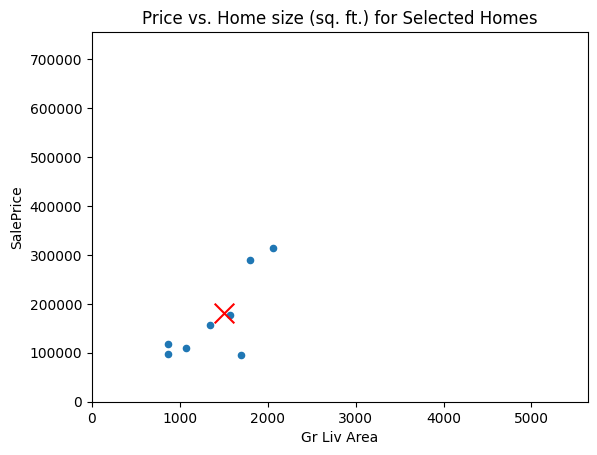

In [34]:
homes_of_interest = [100,200, 300, 400, 500, 600, 700, 800 ]
home = df_ames.iloc[homes_of_interest ][['Gr Liv Area','SalePrice']]
home
ax = home.plot.scatter(x='Gr Liv Area', y='SalePrice',
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                               title = 'Price vs. Home size (sq. ft.) for Selected Homes',
                               )
means.to_frame().T.plot.scatter(x='Gr Liv Area', y='SalePrice',
                                c='red', marker = 'x', ax =ax,
                                s = 200)    ### X is now of bigger size

<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

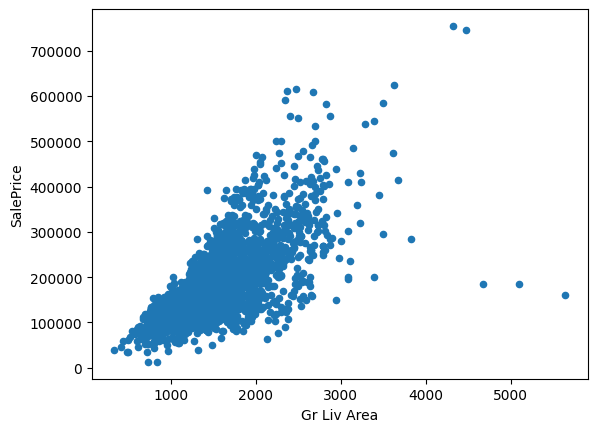

In [35]:
df_ames.plot.scatter(x="Gr Liv Area", y="SalePrice")

<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

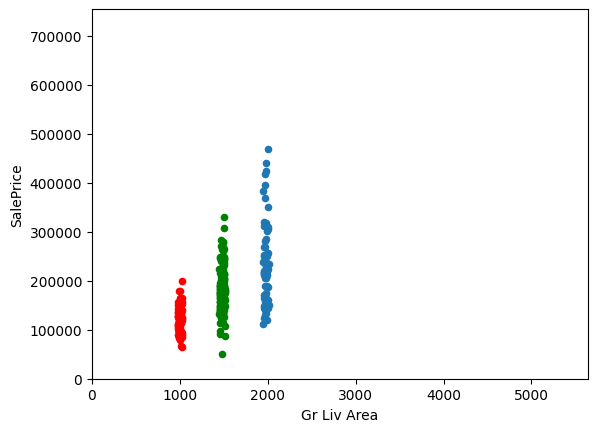

In [36]:
axy =df_ames[(df_ames['Gr Liv Area'] >=  1950) & (df_ames['Gr Liv Area']<= 2010)].plot.scatter(x="Gr Liv Area", y="SalePrice",
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()))
df_ames[(df_ames['Gr Liv Area'] >=  975) & (df_ames['Gr Liv Area']<= 1025)].plot.scatter(x="Gr Liv Area", y="SalePrice",
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                                c='red',  ax= axy)
df_ames[(df_ames['Gr Liv Area'] >=  1450) & (df_ames['Gr Liv Area']<= 1510)].plot.scatter(x="Gr Liv Area", y="SalePrice",
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                                c='green',  ax= axy)

<Axes: title={'center': 'Price vs. Home Size (sq. ft.) for Ames, IA Home Sales'}, xlabel='Gr Liv Area', ylabel='SalePrice'>

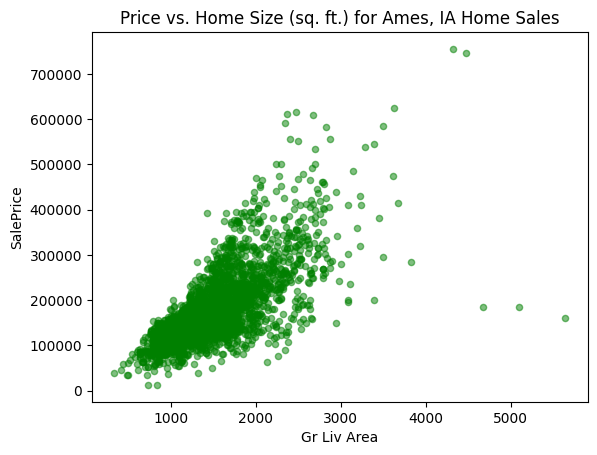

In [37]:
df_ames.plot.scatter(x="Gr Liv Area", y="SalePrice",
                     title = 'Price vs. Home Size (sq. ft.) for Ames, IA Home Sales',
                     c = 'green',
                     alpha = 0.5)

<Axes: title={'center': 'Price vs. Home Size (sq. ft.) for Ames, IA Home Sales'}, xlabel='Gr Liv Area', ylabel='SalePrice'>

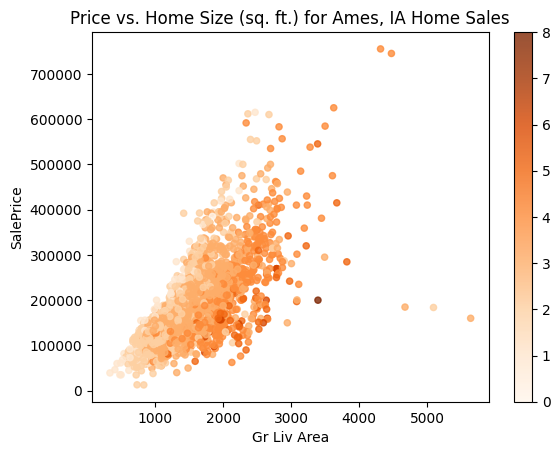

In [38]:
df_ames.plot.scatter(x="Gr Liv Area", y="SalePrice",
                     title = 'Price vs. Home Size (sq. ft.) for Ames, IA Home Sales',
                     c = df_ames['Bedroom AbvGr'],
                     cmap= 'Oranges',
                     alpha =(0.8))

In [39]:
df_ames['Bedroom AbvGr'].head()

0    3
1    2
2    3
3    3
4    3
Name: Bedroom AbvGr, dtype: int64

<Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>

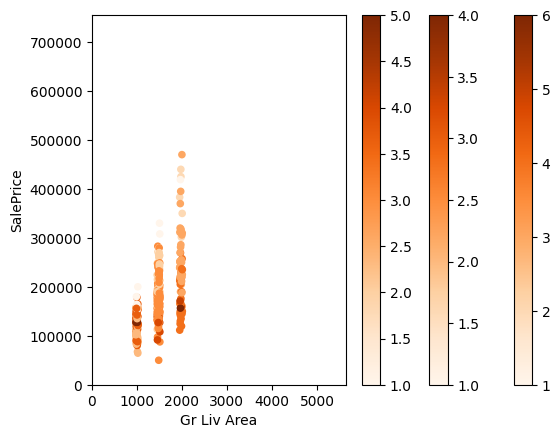

In [40]:
d1 = df_ames[(df_ames['Gr Liv Area'] >=  1950) & (df_ames['Gr Liv Area']<= 2010)]
d2= df_ames[(df_ames['Gr Liv Area'] >=  975) & (df_ames['Gr Liv Area']<= 1025)]
d3 = df_ames[(df_ames['Gr Liv Area'] >=  1450) & (df_ames['Gr Liv Area']<= 1510)]
axy = d1.plot.scatter(x="Gr Liv Area", y="SalePrice",       xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                                 c = d1['Bedroom AbvGr'],
                                cmap = 'Oranges')
d2.plot.scatter(x="Gr Liv Area", y="SalePrice",
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                                 c = d2['Bedroom AbvGr'],
                            cmap = 'Oranges',
                                ax= axy)
d3.plot.scatter(x="Gr Liv Area", y="SalePrice",
                               xlim = (0,df_ames['Gr Liv Area'].max()),
                               ylim = (0,df_ames.SalePrice.max()),
                               c = d3['Bedroom AbvGr'],
                              cmap = 'Oranges',
                               ax= axy)

In [41]:
df_ames["Gr Liv Area"].cov(df_ames["SalePrice"])

np.float64(28542199.568276513)

In [42]:
df_ames["Gr Liv Area"].corr(df_ames["SalePrice"])

np.float64(0.706779920976628)

In [43]:
df_ames["SalePrice"].corr(df_ames["Gr Liv Area"])

np.float64(0.7067799209766279)